In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import copy as cp

In [2]:
df = pd.read_csv(r"C:\Users\SHREYAS ROY\Desktop\Manipal Work Documents\titanic.csv")
df['Title'] = (
    df['Name']
    .str.extract(r',\s*([^\.]+)\.', expand=False)
    .str.strip()
    .replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
)
valid_titles = ['Mr', 'Mrs', 'Miss', 'Master']
df['Title'] = df['Title'].where(df['Title'].isin(valid_titles), 'Rare')

df['Age'] = df['Age'].fillna(df.groupby('Title')['Age'].transform('median'))
df['Age'] = df['Age'].fillna(df['Age'].median())

train = df.sample(frac=0.8, random_state=42)
test  = df.drop(train.index)

<Axes: title={'center': 'Correlation with Target'}>

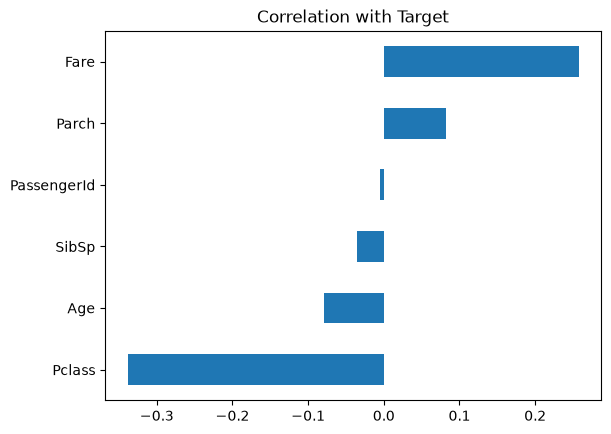

In [3]:
numCols = df.select_dtypes(include = np.number).columns
corr = df[numCols].corr()
corr['Survived'].drop('Survived').sort_values().plot.barh(title = 'Correlation with Target')

In [4]:
train = train.dropna() 
test = test.dropna()
train = pd.get_dummies(train, columns = ['Sex', 'Embarked'], drop_first = True)
train = train.drop(['PassengerId', 'Cabin', 'Name', 'Ticket','Title'], axis = 1) 
test = pd.get_dummies(test, columns = ['Sex', 'Embarked'], drop_first = True)
test = test.drop(['PassengerId', 'Cabin', 'Name', 'Ticket', 'Title'], axis = 1)

test = test.reindex(columns=train.columns, fill_value=0)
print(train.head())

     Survived  Pclass   Age  SibSp  Parch     Fare  Sex_male  Embarked_Q  \
136         1       1  19.0      0      2  26.2833     False       False   
137         0       1  37.0      1      0  53.1000      True       False   
853         1       1  16.0      0      1  39.4000     False       False   
621         1       1  42.0      1      0  52.5542      True       False   
110         0       1  47.0      0      0  52.0000      True       False   

     Embarked_S  
136        True  
137        True  
853        True  
621        True  
110        True  


In [5]:
targetCol = 'Survived'
rawFeatures = train.drop(columns = [targetCol]).to_numpy()
target = train[targetCol].to_numpy()# reshape() is used to avoid Broadcasting Mismatch
rawTestFeatures = test.drop(columns = [targetCol]).to_numpy()
testCases = test[targetCol].to_numpy()

In [6]:
rawFeatures = rawFeatures.astype(np.float64) 
rawTestFeatures = rawTestFeatures.astype(np.float64)

# Z-Score Normalization
mean = np.mean(rawFeatures, axis=0)
std = np.std(rawFeatures, axis=0)
std[std == 0] = 1.0
features = (rawFeatures - mean) / std 
testFeatures = (rawTestFeatures - mean) / std
print(features)

[[-0.36867646 -1.05506956 -0.6800366  ... -1.0662956  -0.14002801
   0.77990219]
 [-0.36867646  0.1120483   0.9033322  ...  0.93782625 -0.14002801
   0.77990219]
 [-0.36867646 -1.2495892  -0.6800366  ... -1.0662956  -0.14002801
   0.77990219]
 ...
 [-0.36867646 -0.2121511  -0.6800366  ...  0.93782625 -0.14002801
  -1.28221207]
 [-0.36867646  0.17688818  0.9033322  ...  0.93782625 -0.14002801
   0.77990219]
 [-0.36867646 -1.11990944  0.9033322  ...  0.93782625 -0.14002801
  -1.28221207]]


In [7]:
def costFunction(x, y, w, b):
    m = x.shape[0]
    f_wb = np.dot(x,w) + b 
    f_wb = np.clip(f_wb, -500, 500)
    g_wb = 1 / (1 + np.exp(-f_wb)) 
    g_wb = np.clip(g_wb, 1e-15, 1 - 1e-15)
    
    cost = - np.dot(y, np.log(g_wb)) - np.dot((1 - y) , np.log(1 - g_wb))
    totalCost = np.sum(cost) / m
    return totalCost
def computeGradient(x, y, w, b):
    m = x.shape[0]
    dw, db = 0, 0
    f_wb = np.dot(x,w) + b 
    f_wb = np.clip(f_wb, -500, 500)
    g_wb = 1 / (1 + np.exp(-f_wb))
    g_wb = np.clip(g_wb, 1e-15, 1 - 1e-15)
    error = g_wb - y
    dw = np.dot(x.T, error) / m
    db = np.sum(error) / m
    return dw, db
def gradientDescent(features, target, wIn, b, alpha, iterations):
    m = features.shape[0]
    J_history = []
    w = cp.deepcopy(wIn)
    for i in range(0, iterations + 1):
        dw, db = computeGradient(features, target, w, b)
        w = w - alpha * dw
        b = b - alpha * db
        cost = costFunction(features, target, w, b)
        J_history.append(cost)
        if i % (iterations // 10) == 0:
            print(f"Iteration {i:4}: Cost {float(J_history[-1]): .6f}   ")
    return w, b, J_history

In [9]:
wIn = np.zeros(features.shape[1], dtype = np.float64)
w, b , J_history = gradientDescent(features, target, wIn, 0, 0.1, 2_000) # Ensure iterations >= 10

Iteration    0: Cost  0.680118   
Iteration  200: Cost  0.411740   
Iteration  400: Cost  0.405767   
Iteration  600: Cost  0.404880   
Iteration  800: Cost  0.404700   
Iteration 1000: Cost  0.404659   
Iteration 1200: Cost  0.404649   
Iteration 1400: Cost  0.404647   
Iteration 1600: Cost  0.404646   
Iteration 1800: Cost  0.404646   
Iteration 2000: Cost  0.404646   


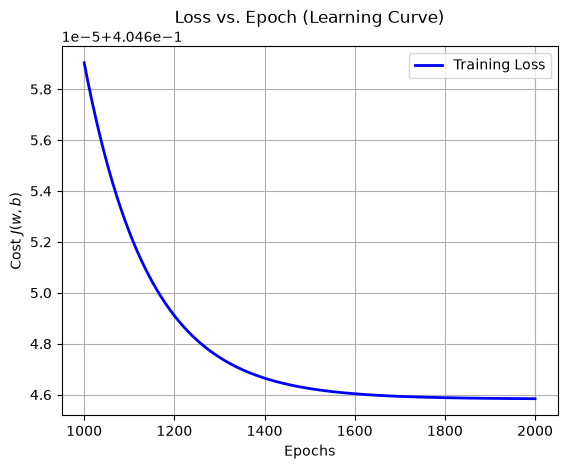

In [10]:
f_wb = np.dot(features, w) + b
f_wb = np.clip(f_wb, -500, 500)
yPred = 1 / (1 + np.exp(-f_wb))
yPred = (yPred >= 0.5).astype(int)

# Confusian Matrix:
tp = np.sum((target == 1) & (yPred == 1))
tn = np.sum((target == 0) & (yPred == 0))
fp = np.sum((target == 0) & (yPred == 1))
fn = np.sum((target == 1) & (yPred == 0))

plt.plot(range(1000, len(J_history)), J_history[1000:], color='blue', linewidth=2, label='Training Loss')
plt.title('Loss vs. Epoch (Learning Curve)')
plt.xlabel('Epochs')
plt.ylabel('Cost $J(w,b)$')
plt.grid(True)
plt.legend()
plt.show()

In [13]:
f_wb = np.dot(features, w) + b
f_wb = np.clip(f_wb, -500, 500)
predictedVal = 1 / (1 + np.exp(-f_wb))
predictedVal = (predictedVal >= 0.5).astype(int)

# Confusian Matrix:
tp = np.sum((target == 1) & (predictedVal == 1))
tn = np.sum((target == 0) & (predictedVal == 0))
fp = np.sum((target == 0) & (predictedVal == 1))
fn = np.sum((target == 1) & (predictedVal == 0))

accuracy = (tp + tn) / len(target) 
precision = tp / (tp + fp) 
recall = tp / (tp + fn)
f1 = 2 * (precision * recall) / (precision + recall)
testCost = costFunction(features, target, w, b)

print("TRAINING SET EVALUATION:")
print(f"Test Cost J(w,b)     : {testCost: .4f}")
print(f"Accuracy             : {accuracy * 100:.2f}%")
print(f"Precision            : {precision * 100:.2f}%")
print(f"Recall/Sensitivity   : {recall * 100:.2f}%")
print(f"F1 Score             : {f1: .4f}")

print("CONFUSION MATRIX:")
print(f"                  Pred Neg (0)   Pred Pos (1)")
print(f"Actual Neg (0)      {tn:8d}       {fp:8d}")
print(f"Actual Pos (1)      {fn:8d}       {tp:8d}")

TRAINING SET EVALUATION:
Test Cost J(w,b)     :  0.4046
Accuracy             : 79.49%
Precision            : 87.00%
Recall/Sensitivity   : 82.08%
F1 Score             :  0.8447
CONFUSION MATRIX:
                  Pred Neg (0)   Pred Pos (1)
Actual Neg (0)            37             13
Actual Pos (1)            19             87


In [14]:
f_wb = np.dot(testFeatures, w) + b
f_wb = np.clip(f_wb, -500, 500)
predictedVal = 1 / (1 + np.exp(-f_wb))
predictedVal = (predictedVal >= 0.5).astype(int)

# Confusian Matrix:
tp = np.sum((testCases == 1) & (predictedVal == 1))
tn = np.sum((testCases == 0) & (predictedVal == 0))
fp = np.sum((testCases == 0) & (predictedVal == 1))
fn = np.sum((testCases == 1) & (predictedVal == 0))

accuracy = (tp + tn) / len(testCases) 
precision = tp / (tp + fp) 
recall = tp / (tp + fn)
f1 = 2 * (precision * recall) / (precision + recall)
testCost = costFunction(testFeatures, testCases, w, b)

print("TEST SET EVALUATION:")
print(f"Test Cost J(w,b)     : {testCost: .4f}")
print(f"Accuracy             : {accuracy * 100:.2f}%")
print(f"Precision            : {precision * 100:.2f}%")
print(f"Recall/Sensitivity   : {recall * 100:.2f}%")
print(f"F1 Score             : {f1: .4f}")

print("CONFUSION MATRIX:")
print(f"                  Pred Neg (0)   Pred Pos (1)")
print(f"Actual Neg (0)      {tn:8d}       {fp:8d}")
print(f"Actual Pos (1)      {fn:8d}       {tp:8d}")

TEST SET EVALUATION:
Test Cost J(w,b)     :  0.6232
Accuracy             : 76.09%
Precision            : 79.31%
Recall/Sensitivity   : 82.14%
F1 Score             :  0.8070
CONFUSION MATRIX:
                  Pred Neg (0)   Pred Pos (1)
Actual Neg (0)            12              6
Actual Pos (1)             5             23
